In [13]:
import io
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [14]:

# 1. Define the official UCI repository direct download URL for the dataset archive
url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

print("Downloading dataset...")

# 2. Download the outer zip file from the web into memory as bytes and open it
outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))

# 3. Open the inner zip file ('UCI HAR Dataset.zip') which is nested inside the outer zip archive
inner = zipfile.ZipFile(io.BytesIO(outer.read("UCI HAR Dataset.zip")))


def load(split):
  """Helper function to load raw time-series inertial signals,

  activity labels, and subject IDs for a given split ('train' or 'test').
  """
  # Construct the base directory path inside the zip file for the requested split
  d = f"UCI HAR Dataset/{split}/"

  # Find, filter, and sort all text files belonging to the 9 raw inertial signal measurements
  names = sorted(
      n
      for n in inner.namelist()
      if n.startswith(d + "Inertial Signals/") and n.endswith(".txt")
  )

  # Load each text file into a NumPy array and stack them along axis=1
  # This creates a 3D tensor of shape: (n_samples, 9_signals, 128_time_steps)
  X = np.stack([np.loadtxt(inner.open(n)) for n in names], axis=1)

  # Load the corresponding activity class labels (integers 1 to 6) for each window
  y = np.loadtxt(inner.open(d + f"y_{split}.txt"), dtype=int)

  # Load the subject IDs for each window (critical for subject-based splitting to prevent data leakage)
  s = np.loadtxt(inner.open(d + f"subject_{split}.txt"), dtype=int)

  return X, y, s


# 4. Load the complete training dataset (7,352 windows across 21 subjects)
X_train, y_train, s_train = load("train")

# 5. Load the complete test dataset (2,947 windows across 9 unseen subjects)
X_test, y_test, s_test = load("test")

print("Dataset loaded successfully!")
# Print out the resulting tensor shapes to verify everything loaded correctly
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

Dataset loaded successfully!
X_train shape: (7352, 9, 128), y_train shape: (7352,)
X_test shape: (2947, 9, 128), y_test shape: (2947,)


1. Training Data (X_train and y_train)

    X_train shape: (7352, 9, 128)

        7352: You have 7,352 distinct time windows (individual data snippets) in your training set.

        9: Each window contains 9 inertial signals (body acceleration, total acceleration, and angular velocity, across the X, Y, and Z axes).

        128: Each signal has 128 time steps (representing 2.56 seconds of movement captured at 50 Hz).

    y_train shape: (7352,)

        This is a 1D array containing 7,352 activity labels (integers from 1 to 6, representing walking, sitting, standing, etc.)—one label matching each of your 7,352 training windows.

2. Test Data (X_test and y_test)

    X_test shape: (2947, 9, 128)

        You have 2,947 test windows from a separate group of users (the 9 test subjects) with the exact same 9 signals and 128 time steps.

    y_test shape: (2947,)

        The corresponding 2,947 activity labels for the test windows, used to evaluate how
        well your trained model generalizes to people it has never seen before.

Extract features(3D to 2D)

In [24]:


signal_names = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]

stat_names = ["mean", "std", "min", "max", "energy"]
feature_names = [f"{sig}_{stat}" for stat in stat_names for sig in signal_names]


def to_2d_features(X):
  """Turn 3D array (n_samples, 9, 128) into a 2D NumPy array and DataFrame of shape (n_samples, 45)."""
  means = np.mean(X, axis=2)
  stds = np.std(X, axis=2)
  mins = np.min(X, axis=2)
  maxs = np.max(X, axis=2)
  energies = np.mean(X**2, axis=2)

  X_2d = np.hstack([means, stds, mins, maxs, energies])
  df_2d = pd.DataFrame(X_2d, columns=feature_names)
  return X_2d, df_2d


# Convert both splits separately to 2D
X_train_2d, df_train_2d = to_2d_features(X_train)
X_test_2d, df_test_2d = to_2d_features(X_test)

print("X_train_2d shape:", X_train_2d.shape)
print("X_test_2d shape:", X_test_2d.shape)
df_train_2d.head()

X_train_2d shape: (7352, 45)
X_test_2d shape: (2947, 45)


,body_acc_x_mean,body_acc_y_mean,body_acc_z_mean,body_gyro_x_mean,body_gyro_y_mean,body_gyro_z_mean,...,body_gyro_x_energy,body_gyro_y_energy,body_gyro_z_energy,total_acc_x_energy,total_acc_y_energy,total_acc_z_energy
0,0.002269,-0.001655,-0.008126,0.022250,0.019403,0.009468,...,0.000703,0.000770,0.000125,1.038985,0.015452,0.009962
1,0.000174,0.000382,-0.005025,0.011926,-0.004314,0.006308,...,0.000409,0.000126,0.000095,1.039278,0.015137,0.009421
2,0.000428,-0.001222,-0.001703,-0.004150,-0.012640,0.004335,...,0.000513,0.000208,0.000095,1.040259,0.015666,0.008668
3,0.000329,-0.004753,-0.004947,-0.016228,-0.007697,-0.000352,...,0.000347,0.000120,0.000067,1.041119,0.017045,0.007708
4,-0.000195,0.000298,-0.002330,-0.006483,-0.000166,-0.003957,...,0.000254,0.000061,0.000084,1.040925,0.016969,0.007238


In [5]:
print("X_train_2d shape (ndim =", X_train_2d.ndim, "):", X_train_2d.shape)
print("X_test_2d shape  (ndim =", X_test_2d.ndim, "):", X_test_2d.shape)
print("df_train_2d shape:", df_train_2d.shape)
print(df_train_2d.head(3))

X_train_2d shape (ndim = 2 ): (7352, 45)
X_test_2d shape  (ndim = 2 ): (2947, 45)
df_train_2d shape: (7352, 45)
   body_acc_x_mean  body_acc_y_mean  body_acc_z_mean  body_gyro_x_mean  \
0         0.002269        -0.001655        -0.008126          0.022250   
1         0.000174         0.000382        -0.005025          0.011926   
2         0.000428        -0.001222        -0.001703         -0.004150   

   body_gyro_y_mean  body_gyro_z_mean  total_acc_x_mean  total_acc_y_mean  \
0          0.019403          0.009468          1.019305         -0.124262   
1         -0.004314          0.006308          1.019448         -0.122936   
2         -0.012640          0.004335          1.019927         -0.124997   

   total_acc_z_mean  body_acc_x_std  ...  total_acc_z_max  body_acc_x_energy  \
0          0.099732        0.002941  ...         0.109485           0.000014   
1          0.096939        0.001981  ...         0.105788           0.000004   
2          0.092897        0.002908  ...  

Test Accuracy: 0.8392 (83.92%)

                    precision    recall  f1-score   support

           WALKING     0.7367    0.8347    0.7826       496
  WALKING_UPSTAIRS     0.7691    0.7070    0.7367       471
WALKING_DOWNSTAIRS     0.8180    0.8238    0.8209       420
           SITTING     0.8915    0.7862    0.8355       491
          STANDING     0.8274    0.9098    0.8666       532
            LAYING     0.9980    0.9497    0.9733       537

          accuracy                         0.8392      2947
         macro avg     0.8401    0.8352    0.8359      2947
      weighted avg     0.8432    0.8392    0.8394      2947

Confusion Matrix (rows = true, cols = predicted):
                    WALKING  WALKING_UPSTAIRS  WALKING_DOWNSTAIRS  SITTING  STANDING  LAYING
WALKING                 414                41                  41        0         0       0
WALKING_UPSTAIRS        101               333                  36        1         0       0
WALKING_DOWNSTAIRS       46         

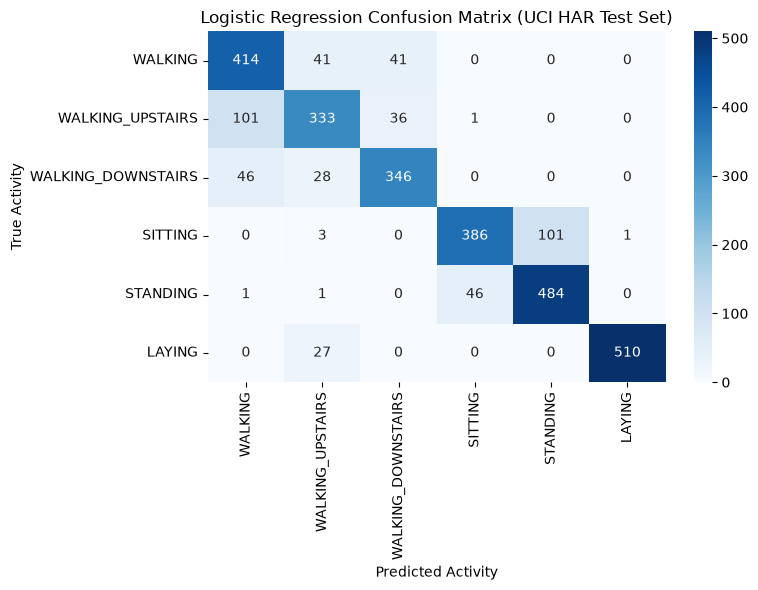

In [25]:
ACTIVITY_LABELS = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING",
}

y_train_names = pd.Series(np.asarray(y_train).ravel()).map(ACTIVITY_LABELS)
y_test_names = pd.Series(np.asarray(y_test).ravel()).map(ACTIVITY_LABELS)
target_names = [ACTIVITY_LABELS[k] for k in sorted(ACTIVITY_LABELS)]

clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
clf.fit(X_train_2d, y_train_names)

y_pred_names = clf.predict(X_test_2d)

acc = accuracy_score(y_test_names, y_pred_names)
print(f"Test Accuracy: {acc:.4f} ({acc * 100:.2f}%)\n")
print(classification_report(y_test_names, y_pred_names, labels=target_names, digits=4))

cm = confusion_matrix(y_test_names, y_pred_names, labels=target_names)
cm_df = pd.DataFrame(cm, index=target_names, columns=target_names)
print("Confusion Matrix (rows = true, cols = predicted):")
print(cm_df)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix (UCI HAR Test Set)")
plt.ylabel("True Activity")
plt.xlabel("Predicted Activity")
plt.tight_layout()
plt.show()

In [19]:
def extract_fft_features(X_3d, signal_names=None, sampling_rate_hz=50.0):
  """Extracts compact frequency-domain features from 3D windows (samples, signals, time_steps).

  Returns:
      X_fft_2d: np.ndarray of shape (n_samples, n_signals * 3)
      feature_names: list of str
  """
  X_3d = np.asarray(X_3d, dtype=np.float64)
  n_samples, n_signals, n_steps = X_3d.shape

  if signal_names is None:
    signal_names = [f"signal_{i}" for i in range(n_signals)]

  # One-sided FFT along the 128 time steps (axis=-1)
  fft_vals = np.fft.rfft(X_3d, axis=-1)
  magnitudes = np.abs(fft_vals)
  power = magnitudes**2
  freqs = np.fft.rfftfreq(n_steps, d=1.0 / sampling_rate_hz)

  # 1. Dominant frequency (Hz)
  dom_idx = np.argmax(magnitudes, axis=-1)
  dom_freq = freqs[dom_idx]

  # 2. Spectral energy (sum of squared magnitudes)
  spectral_energy = np.sum(power, axis=-1)

  # 3. Spectral centroid (power-weighted average frequency)
  total_power = np.sum(power, axis=-1, keepdims=True)
  spectral_centroid = np.divide(
      np.sum(power * freqs, axis=-1),
      np.squeeze(total_power, axis=-1),
      out=np.zeros((n_samples, n_signals), dtype=np.float64),
      where=np.squeeze(total_power, axis=-1) > 0,
  )

  X_fft_2d = np.hstack([dom_freq, spectral_energy, spectral_centroid])

  feature_names = (
      [f"{s}_fft_dom_freq" for s in signal_names]
      + [f"{s}_fft_energy" for s in signal_names]
      + [f"{s}_fft_centroid" for s in signal_names]
  )
  return X_fft_2d, feature_names


# Example: combine your existing X_train_2d / X_test_2d with FFT features
# Pass your signal_names list if you already defined one, e.g. signal_names=signal_names
X_train_fft, fft_cols = extract_fft_features(X_train)
X_test_fft, _ = extract_fft_features(X_test)

X_train_combined = np.hstack([X_train_2d, X_train_fft])
X_test_combined = np.hstack([X_test_2d, X_test_fft])

clf_fft = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
clf_fft.fit(X_train_combined, y_train_names)
y_pred_fft = clf_fft.predict(X_test_combined)

acc_fft = accuracy_score(y_test_names, y_pred_fft)
print(f"Combined (Time + FFT) Test Accuracy: {acc_fft:.4f} ({acc_fft * 100:.2f}%)")
print("Combined shape:", X_train_combined.shape, X_test_combined.shape)

Combined (Time + FFT) Test Accuracy: 0.9006 (90.06%)
Combined shape: (7352, 72) (2947, 72)


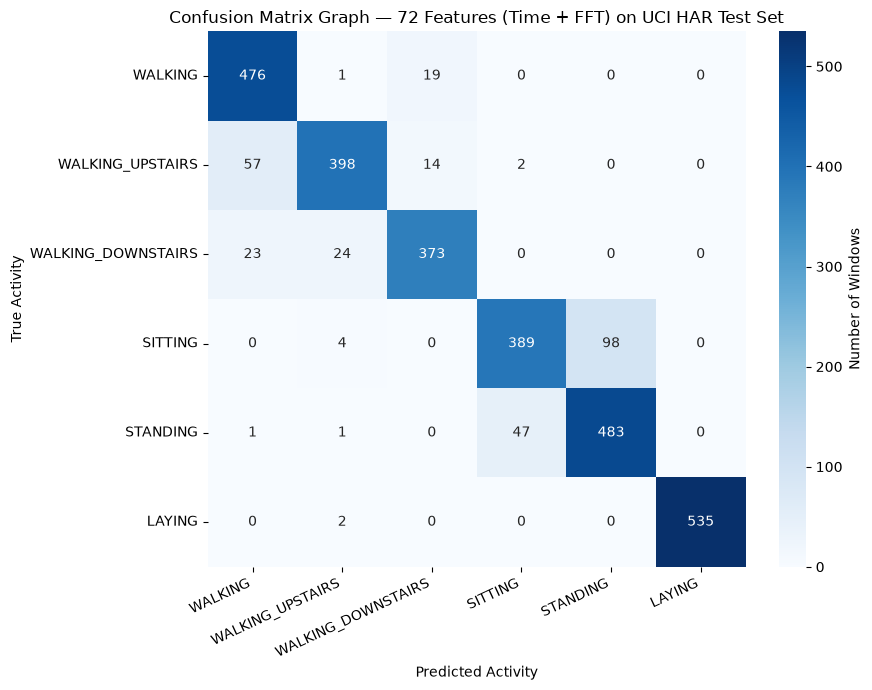

In [26]:
cm_fft = confusion_matrix(y_test_names, y_pred_fft, labels=target_names)
cm_fft_df = pd.DataFrame(cm_fft, index=target_names, columns=target_names)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_fft_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar_kws={"label": "Number of Windows"},
)
plt.title(
    "Confusion Matrix Graph — 72 Features (Time + FFT) on UCI HAR Test Set"
)
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
ACTIVITY_LABELS = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING",
}
target_names = [ACTIVITY_LABELS[k] for k in sorted(ACTIVITY_LABELS)]

# Ensure string labels are aligned
y_test_eval = pd.Series(np.asarray(y_test).ravel()).map(
    lambda v: ACTIVITY_LABELS.get(v, v)
)

# 1. Baseline (45 Time-Domain Features)
y_pred_time = clf.predict(X_test_2d)
y_pred_time_eval = pd.Series(np.asarray(y_pred_time).ravel()).map(
    lambda v: ACTIVITY_LABELS.get(v, v)
)

# 2. Combined (72 Time + FFT Features)
y_pred_fft_eval = pd.Series(np.asarray(y_pred_fft).ravel()).map(
    lambda v: ACTIVITY_LABELS.get(v, v)
)

print("=== 1. 45 Time-Domain Features (Baseline: 83.92%) ===")
print(
    classification_report(
        y_test_eval, y_pred_time_eval, labels=target_names, digits=4
    )
)

print("=== 2. 72 Time + FFT Features (Combined: 90.06%) ===")
print(
    classification_report(
        y_test_eval, y_pred_fft_eval, labels=target_names, digits=4
    )
)

rep_time = classification_report(
    y_test_eval, y_pred_time_eval, labels=target_names, output_dict=True
)
rep_fft = classification_report(
    y_test_eval, y_pred_fft_eval, labels=target_names, output_dict=True
)

metrics_table = pd.DataFrame(
    {
        "support": [int(rep_time[c]["support"]) for c in target_names],
        "prec_time_45": [rep_time[c]["precision"] for c in target_names],
        "prec_fft_72": [rep_fft[c]["precision"] for c in target_names],
        "rec_time_45": [rep_time[c]["recall"] for c in target_names],
        "rec_fft_72": [rep_fft[c]["recall"] for c in target_names],
        "f1_time_45": [rep_time[c]["f1-score"] for c in target_names],
        "f1_fft_72": [rep_fft[c]["f1-score"] for c in target_names],
    },
    index=target_names,
).round(4)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 12)
print("=== Side-by-Side Precision, Recall, F1 & Support ===")
print(metrics_table)

=== 1. 45 Time-Domain Features (Baseline: 83.92%) ===
                    precision    recall  f1-score   support

           WALKING     0.7367    0.8347    0.7826       496
  WALKING_UPSTAIRS     0.7691    0.7070    0.7367       471
WALKING_DOWNSTAIRS     0.8180    0.8238    0.8209       420
           SITTING     0.8915    0.7862    0.8355       491
          STANDING     0.8274    0.9098    0.8666       532
            LAYING     0.9980    0.9497    0.9733       537

          accuracy                         0.8392      2947
         macro avg     0.8401    0.8352    0.8359      2947
      weighted avg     0.8432    0.8392    0.8394      2947

=== 2. 72 Time + FFT Features (Combined: 90.06%) ===
                    precision    recall  f1-score   support

           WALKING     0.8546    0.9597    0.9041       496
  WALKING_UPSTAIRS     0.9256    0.8450    0.8835       471
WALKING_DOWNSTAIRS     0.9187    0.8881    0.9031       420
           SITTING     0.8881    0.7923    0.8375

In [32]:
feature_names = (
    list(df_train_2d.columns) + fft_cols
)  # or just list(df_train_2d.columns) for 45 features
model = clf_fft.named_steps["logisticregression"]
classes = model.classes_

for idx, act in enumerate(classes):
  weights = model.coef_[idx]
  top_pos = np.argsort(weights)[-3:][::-1]
  top_neg = np.argsort(weights)[:3]
  print(f"\n=== {act} ===")
  print(
      "  Top + features:",
      [(feature_names[i], round(weights[i], 3)) for i in top_pos],
  )
  print(
      "  Top - features:",
      [(feature_names[i], round(weights[i], 3)) for i in top_neg],
  )


=== LAYING ===
  Top + features: [('total_acc_y_energy', np.float64(1.274)), ('total_acc_y_fft_energy', np.float64(1.266)), ('total_acc_y_max', np.float64(0.696))]
  Top - features: [('total_acc_x_mean', np.float64(-1.6)), ('total_acc_x_min', np.float64(-1.584)), ('total_acc_x_fft_energy', np.float64(-1.211))]

=== SITTING ===
  Top + features: [('body_gyro_x_min', np.float64(2.309)), ('total_acc_x_min', np.float64(1.687)), ('body_gyro_x_energy', np.float64(1.589))]
  Top - features: [('body_gyro_x_std', np.float64(-2.289)), ('body_gyro_x_max', np.float64(-1.867)), ('body_acc_x_max', np.float64(-1.168))]

=== STANDING ===
  Top + features: [('body_gyro_x_max', np.float64(1.741)), ('body_acc_y_min', np.float64(1.505)), ('body_gyro_x_std', np.float64(1.406))]
  Top - features: [('body_gyro_x_fft_energy', np.float64(-2.616)), ('body_gyro_x_energy', np.float64(-2.513)), ('body_gyro_x_min', np.float64(-1.482))]

=== WALKING ===
  Top + features: [('body_acc_x_fft_centroid', np.float64(1.92

In [30]:
# 1. Check ndim and shape of common arrays in your notebook
for var_name in ["X_train", "X_test", "X_train_72", "X_test_72", "y_test"]:
  if var_name in globals():
    arr = globals()[var_name]
    print(f"{var_name:12s} -> ndim={arr.ndim}, shape={arr.shape}")

# 2. Find list/Index variables that look like feature names
print("\nPossible feature name variables:")
for name, val in globals().items():
  if not name.startswith("_") and isinstance(val, (list, tuple)):
    if len(val) > 0 and isinstance(val[0], str):
      print(f"  {name} (len={len(val)}): first 3 -> {val[:3]}")

X_train      -> ndim=3, shape=(7352, 9, 128)
X_test       -> ndim=3, shape=(2947, 9, 128)
y_test       -> ndim=1, shape=(2947,)

Possible feature name variables:
  In (len=31): first 3 -> ['', 'import io\nimport urllib.request\nimport zipfile\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nfrom sklearn.inspection import permutation_importance\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (\n    accuracy_score,\n    classification_report,\n    confusion_matrix,\n)\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler', 'import io\nimport urllib.request\nimport zipfile\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nfrom sklearn.inspection import permutation_importance\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (\n    accuracy_score,\n    classification_report,\n    confus

In [31]:
# Rename signal_<i>_... entries in both fft_cols and feature_names
rename_map = {
    f"signal_{i}_{suffix}": f"{sig}_{suffix}"
    for i, sig in enumerate(signal_names)
    for suffix in ["fft_dom_freq", "fft_energy", "fft_centroid"]
}

fft_cols = [rename_map.get(c, c) for c in fft_cols]
feature_names = [rename_map.get(c, c) for c in feature_names]

print(
    "Remaining 'signal_' names:",
    [c for c in feature_names if c.startswith("signal_")],
)
print("First 3 renamed fft_cols:", fft_cols[:3])

Remaining 'signal_' names: []
First 3 renamed fft_cols: ['body_acc_x_fft_dom_freq', 'body_acc_y_fft_dom_freq', 'body_acc_z_fft_dom_freq']


Find the missclassified window.

In [39]:
X_test_feat = X_test_combined
pipe = clf_fft

steps = list(pipe.named_steps.values())
scaler = steps[0]
lr_model = steps[-1]

X_test_sc = scaler.transform(X_test_feat)
y_pred = pipe.predict(X_test_feat)
y_proba = pipe.predict_proba(X_test_feat)

# Map integer y_test (1..6) to activity names using target_names order
if np.issubdtype(y_test.dtype, np.integer):
  id_to_name = {i + 1: name for i, name in enumerate(target_names)}
  y_test_str = np.array([id_to_name[int(v)] for v in y_test])
else:
  y_test_str = np.asarray(y_test).astype(str)

y_pred_str = np.asarray(y_pred).astype(str)

# Use lr_model.classes_ so coef_ rows and predict_proba columns match 100%
classes_list = list(lr_model.classes_)
idx_sit = classes_list.index("SITTING")
idx_std = classes_list.index("STANDING")

wrong_indices = np.where((y_test_str == "SITTING") & (y_pred_str == "STANDING"))[
    0
]
print(f"Total SITTING windows predicted as STANDING: {len(wrong_indices)}")

# Positive w_diff pushes toward STANDING; negative pushes toward SITTING
w_diff = lr_model.coef_[idx_std] - lr_model.coef_[idx_sit]

sample_indices = wrong_indices[:3]
for idx in sample_indices:
  x_row = X_test_sc[idx]
  contribs = w_diff * x_row
  p_sit, p_std = y_proba[idx, idx_sit], y_proba[idx, idx_std]

  print(
      f"\n--- Test Window #{idx} | P(SITTING)={p_sit:.3f},"
      f" P(STANDING)={p_std:.3f} ---"
  )
  print("  Top features pushing STANDING (+):")
  for j in np.argsort(contribs)[::-1][:3]:
    print(
        f"    {feature_names[j]:28s} | x_sc={x_row[j]:+.2f} |"
        f" contrib={contribs[j]:+.3f}"
    )
  print("  Top features pushing SITTING (-):")
  for j in np.argsort(contribs)[:2]:
    print(
        f"    {feature_names[j]:28s} | x_sc={x_row[j]:+.2f} |"
        f" contrib={contribs[j]:+.3f}"
    )

Total SITTING windows predicted as STANDING: 98

--- Test Window #31 | P(SITTING)=0.283, P(STANDING)=0.717 ---
  Top features pushing STANDING (+):
    body_gyro_x_energy           | x_sc=-0.67 | contrib=+2.766
    body_gyro_x_fft_energy       | x_sc=-0.66 | contrib=+2.685
    total_acc_y_max              | x_sc=-0.81 | contrib=+1.879
  Top features pushing SITTING (-):
    body_gyro_x_std              | x_sc=-0.85 | contrib=-3.149
    body_gyro_x_max              | x_sc=-0.85 | contrib=-3.083

--- Test Window #32 | P(SITTING)=0.175, P(STANDING)=0.825 ---
  Top features pushing STANDING (+):
    body_gyro_x_energy           | x_sc=-0.68 | contrib=+2.776
    body_gyro_x_fft_energy       | x_sc=-0.66 | contrib=+2.698
    total_acc_y_max              | x_sc=-0.92 | contrib=+2.122
  Top features pushing SITTING (-):
    body_gyro_x_std              | x_sc=-0.87 | contrib=-3.223
    body_gyro_x_max              | x_sc=-0.86 | contrib=-3.107

--- Test Window #33 | P(SITTING)=0.464, P(STANDIN

Finding the smallest counter factuals

In [42]:
MAX_SD = 10.0
STEPS = 2000


def find_smallest_1feat_cf(
    x_row_sc, target_str="SITTING", max_sd=MAX_SD, steps=STEPS
):
  target_idx = list(lr_model.classes_).index(target_str)
  # Test smallest |delta| first
  deltas = np.linspace(-max_sd, max_sd, steps)
  deltas = [
      float(d) for d in sorted(deltas, key=lambda v: abs(v)) if float(d) != 0.0
  ]

  n_feat = len(x_row_sc)
  coef = lr_model.coef_
  intercept = lr_model.intercept_

  for d in deltas:
    # Build all n_feat single-feature perturbation candidates at once: shape (n_feat, n_feat)
    cands = np.tile(x_row_sc, (n_feat, 1))
    cands[np.arange(n_feat), np.arange(n_feat)] += d

    logits = cands @ coef.T + intercept
    preds = lr_model.classes_[np.argmax(logits, axis=1)]

    matches = np.where(preds == target_str)[0]
    if len(matches) > 0:
      j = int(matches[0])
      cand_j = cands[j]
      orig_before = scaler.mean_[j] + x_row_sc[j] * scaler.scale_[j]
      orig_after = scaler.mean_[j] + cand_j[j] * scaler.scale_[j]

      # Softmax probability for target class
      exp_l = np.exp(logits[j] - np.max(logits[j]))
      probs = exp_l / np.sum(exp_l)

      return {
          "feat_idx": j,
          "feature": feature_names[j],
          "delta_sd": d,
          "orig_before": float(orig_before),
          "orig_after": float(orig_after),
          "delta_orig": float(orig_after - orig_before),
          "p_sit_after": float(probs[target_idx]),
      }
  return None


counterfactuals = {}
for idx in sample_indices:
  cf = find_smallest_1feat_cf(
      X_test_sc[idx], target_str="SITTING", max_sd=MAX_SD, steps=STEPS
  )
  counterfactuals[idx] = cf
  if cf:
    print(
        f"Window #{idx}: flip via '{cf['feature']}' | "
        f"delta={cf['delta_sd']:+.3f} SD | "
        f"orig: {cf['orig_before']:.4f} -> {cf['orig_after']:.4f} "
        f"(delta={cf['delta_orig']:+.4f}) | "
        f"P(SITTING)_after={cf['p_sit_after']:.3f}"
    )
  else:
    print(f"Window #{idx}: no single-feature flip within +/- {MAX_SD} SD.")

Window #31: flip via 'body_gyro_x_energy' | delta=+0.235 SD | orig: 0.0008 -> 0.0582 (delta=+0.0574) | P(SITTING)_after=0.509
Window #32: flip via 'body_gyro_x_energy' | delta=+0.385 SD | orig: 0.0003 -> 0.0943 (delta=+0.0940) | P(SITTING)_after=0.507
Window #33: flip via 'body_gyro_x_std' | delta=-0.045 SD | orig: 0.0050 -> -0.0070 (delta=-0.0120) | P(SITTING)_after=0.505


Physical Plausibility Summary Table

In [43]:
import pandas as pd

non_neg_tokens = ("_std", "_min", "_max", "_energy", "_fft_energy", "_fft_centroid", "_fft_dom_freq")

rows = []
for idx, cf in counterfactuals.items():
  if cf is None:
    continue
  feat = cf["feature"]
  # Check if a feature that is typically non-negative goes below 0
  could_be_negative = any(tok in feat for tok in ("_std", "_energy", "_fft_energy", "_fft_centroid", "_fft_dom_freq"))
  crosses_zero_downward = could_be_negative and (cf["orig_before"] >= 0) and (cf["orig_after"] < 0)

  if abs(cf["delta_sd"]) <= 1.5 and not crosses_zero_downward:
    plausibility = "Potentially plausible (small shift)"
  elif crosses_zero_downward:
    plausibility = "Unphysical (negative non-negative/spectral metric)"
  else:
    plausibility = "Unlikely / large shift for 2.56s stationary window"

  rows.append({
      "window_idx": int(idx),
      "feature": feat,
      "delta_sd": round(cf["delta_sd"], 3),
      "orig_before": round(cf["orig_before"], 4),
      "orig_after": round(cf["orig_after"], 4),
      "delta_orig": round(cf["delta_orig"], 4),
      "p_sit_after": round(cf["p_sit_after"], 3),
      "plausibility_note": plausibility,
  })

cf_df = pd.DataFrame(rows)
display(cf_df)

,window_idx,feature,delta_sd,orig_before,orig_after,delta_orig,p_sit_after,plausibility_note
0,31,body_gyro_x_energy,0.235,0.0008,0.0582,0.0574,0.509,Potentially plausible (small shift)
1,32,body_gyro_x_energy,0.385,0.0003,0.0943,0.0940,0.507,Potentially plausible (small shift)
2,33,body_gyro_x_std,-0.045,0.0050,-0.0070,-0.0120,0.505,Unphysical (negative non-negative/spectral met...


Error Correction.

In [35]:
items = list(globals().items())

print("2D arrays / DataFrames with 72 columns:")
for k, v in items:
  if k.startswith("_"):
    continue
  if isinstance(v, np.ndarray) and v.ndim == 2 and v.shape[1] == 72:
    print(f"  {k} (ndarray): shape={v.shape}")
  elif isinstance(v, pd.DataFrame) and v.shape[1] == 72:
    print(f"  {k} (DataFrame): shape={v.shape}")

print("\nFitted objects (scaler / model / pipeline):")
for k, v in items:
  if k.startswith("_"):
    continue
  if hasattr(v, "transform") or hasattr(v, "predict"):
    print(f"  {k}: {type(v).__name__}")

2D arrays / DataFrames with 72 columns:
  X_train_combined (ndarray): shape=(7352, 72)
  X_test_combined (ndarray): shape=(2947, 72)

Fitted objects (scaler / model / pipeline):
  LogisticRegression: type
  StandardScaler: type
  df_train_2d: DataFrame
  df_test_2d: DataFrame
  y_train_names: Series
  y_test_names: Series
  clf: Pipeline
  cm_df: DataFrame
  clf_fft: Pipeline
  cm_fft_df: DataFrame
  comparison_df: DataFrame
  y_test_eval: Series
  y_pred_time_eval: Series
  y_pred_fft_eval: Series
  metrics_table: DataFrame
  model: LogisticRegression


Check the baseline data for 561 features.

In [44]:
import os

# Check if 561-feature variables already exist in memory
for var in ['X_train_561', 'X_test_561', 'X_train_orig', 'X_test_orig', 'features_561']:
    if var in globals():
        print(f"Found {var}: shape={getattr(globals()[var], 'shape', len(globals()[var]))}")

# Check dataset directory structure for X_train.txt / features.txt
for root, dirs, files in os.walk('.'):
    for f in files:
        if f in ['X_train.txt', 'X_test.txt', 'features.txt']:
            print(os.path.join(root, f))

In [45]:
import glob, os

print("CWD:", os.getcwd())
for pattern in [
    "**/X_train.txt",
    "**/X_test.txt",
    "**/features.txt",
    "../**/X_train.txt",
    "../**/features.txt",
]:
  for match in glob.glob(pattern, recursive=True):
    print("Found:", match)

CWD: c:\Users\bmkas\Desktop\XAI_&_DW\XAI\Project_XAI


Checking if the .text file is on the disc.

In [46]:
import os

# List files/folders in current dir and two levels up
for p in [".", "..", "../.."]:
  abs_p = os.path.abspath(p)
  print(f"=== {abs_p} ===")
  try:
    print(os.listdir(abs_p))
  except Exception as e:
    print("Error:", e)

# Check any numpy arrays or DataFrames in memory with ~561 columns
import numpy as np, pandas as pd

for name, val in list(globals().items()):
  if isinstance(val, np.ndarray) and val.ndim == 2 and val.shape[1] == 561:
    print(f"Array '{name}': shape={val.shape}")
  elif isinstance(val, pd.DataFrame) and val.shape[1] == 561:
    print(f"DataFrame '{name}': shape={val.shape}")

=== c:\Users\bmkas\Desktop\XAI_&_DW\XAI\Project_XAI ===
['.venv_xai', 'Answer for questions.docx', 'project.ipynb', '~$swer for questions.docx']
=== c:\Users\bmkas\Desktop\XAI_&_DW\XAI ===
['L01_intro_interpretable_models.pdf', 'Project_XAI', 'Wiley_The_Data_Warehouse_Toolkit_The_Definitive_Guide_to_Dimensional.pdf', 'XAI', 'XAI HT2025 Salstentamen 2026-02-27 4hp.pdf', 'XAI(1)', 'XAI(1).zip', 'XAI_labs_work', '__MACOSX']
=== c:\Users\bmkas\Desktop\XAI_&_DW ===
['Data Warehousing', 'RILE', 'XAI']


In [47]:
import os

search_root = ".."
found_files = {}

for root, dirs, files in os.walk(search_root):
  for fname in files:
    if fname in [
        "X_train.txt",
        "X_test.txt",
        "y_train.txt",
        "y_test.txt",
        "features.txt",
        "activity_labels.txt",
    ]:
      found_files.setdefault(fname, []).append(os.path.join(root, fname))

for fname, paths in found_files.items():
  print(f"{fname}:")
  for p in paths:
    print("  ->", os.path.abspath(p))

Unpack the file to my working folder.

In [48]:
import glob, io, os, urllib.request, zipfile

os.makedirs("data", exist_ok=True)
downloads_zip = glob.glob(
    os.path.expanduser("~/Downloads/*human*activity*recognition*.zip")
)

if "inner" in globals():
  # Extract directly from the already-loaded `inner` ZipFile in memory
  inner.extractall("data")
  print("Extracted from `inner` into ./data")
elif downloads_zip:
  # Extract from the zip already in Downloads
  with zipfile.ZipFile(downloads_zip[0], "r") as outer_z:
    nested_bytes = io.BytesIO(outer_z.read("UCI HAR Dataset.zip"))
    with zipfile.ZipFile(nested_bytes, "r") as inner_z:
      inner_z.extractall("data")
  print("Extracted from Downloads zip into ./data")
else:
  # Fallback: download from UCI
  url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
  outer_z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
  nested_bytes = io.BytesIO(outer_z.read("UCI HAR Dataset.zip"))
  with zipfile.ZipFile(nested_bytes, "r") as inner_z:
    inner_z.extractall("data")
  print("Downloaded and extracted into ./data")

# List extracted folders/files
for root, dirs, files in os.walk("data"):
  for f in sorted(files):
    if f in [
        "X_train.txt",
        "X_test.txt",
        "y_train.txt",
        "y_test.txt",
        "features.txt",
        "activity_labels.txt",
    ]:
      print(os.path.join(root, f))

Extracted from `inner` into ./data
data\UCI HAR Dataset\activity_labels.txt
data\UCI HAR Dataset\features.txt
data\UCI HAR Dataset\test\X_test.txt
data\UCI HAR Dataset\test\y_test.txt
data\UCI HAR Dataset\train\X_train.txt
data\UCI HAR Dataset\train\y_train.txt


In [49]:
base_dir = os.path.join("data", "UCI HAR Dataset")

# 1. Load 561 feature names and deduplicate duplicate names (e.g., bandsEnergy())
raw_feats = pd.read_csv(
    os.path.join(base_dir, "features.txt"),
    sep=r"\s+",
    header=None,
    names=["idx", "name"],
)
counts = {}
feat_561_names = []
for name in raw_feats["name"]:
  counts[name] = counts.get(name, 0) + 1
  feat_561_names.append(f"{name}_{counts[name]}" if counts[name] > 1 else name)

print(
    f"561 features loaded: {len(feat_561_names)} total | {len(set(feat_561_names))} unique"
)

# 2. Load train/test feature matrices and activity labels
X_train_561 = pd.read_csv(
    os.path.join(base_dir, "train", "X_train.txt"),
    sep=r"\s+",
    header=None,
    names=feat_561_names,
)
X_test_561 = pd.read_csv(
    os.path.join(base_dir, "test", "X_test.txt"),
    sep=r"\s+",
    header=None,
    names=feat_561_names,
)

act_map = dict(
    pd.read_csv(
        os.path.join(base_dir, "activity_labels.txt"),
        sep=r"\s+",
        header=None,
    ).values
)
y_train_561 = (
    pd.read_csv(
        os.path.join(base_dir, "train", "y_train.txt"),
        sep=r"\s+",
        header=None,
    )[0]
    .map(act_map)
    .values
)
y_test_561 = (
    pd.read_csv(
        os.path.join(base_dir, "test", "y_test.txt"),
        sep=r"\s+",
        header=None,
    )[0]
    .map(act_map)
    .values
)

# 3. Standardize and fit Logistic Regression on the 561 features
scaler_561 = StandardScaler()
X_train_561_sc = scaler_561.fit_transform(X_train_561)
X_test_561_sc = scaler_561.transform(X_test_561)

clf_561 = LogisticRegression(max_iter=1000, random_state=42)
clf_561.fit(X_train_561_sc, y_train_561)

# 4. Compare test accuracy against the 72-feature model (`clf_fft`)
acc_561 = accuracy_score(y_test_561, clf_561.predict(X_test_561_sc))
print(f"561-feature model test accuracy: {acc_561:.4f}")

# Match your 72-feature model variable names (`clf_fft` / `X_test_fft_sc` / `fft_feature_names`)
# Adjust if your notebook used slightly different names:
y_pred_72 = clf_fft.predict(X_test_fft_sc)
y_true_72 = (
    pd.Series(y_test).map(act_map).values
    if np.issubdtype(np.asarray(y_test).dtype, np.integer)
    else y_test
)
acc_72 = accuracy_score(y_true_72, y_pred_72)
print(f"72-feature model test accuracy:  {acc_72:.4f}")

# 5. Global explanation comparison: Top 10 features by mean |coef| across classes
imp_561 = pd.Series(
    np.mean(np.abs(clf_561.coef_), axis=0), index=feat_561_names
).sort_values(ascending=False)
imp_72 = pd.Series(
    np.mean(np.abs(clf_fft.coef_), axis=0), index=fft_feature_names
).sort_values(ascending=False)

print("\nTop 10 features — 72-feature model (mean |coef|):")
print(imp_72.head(10).round(4))

print("\nTop 10 features — 561-feature model (mean |coef|):")
print(imp_561.head(10).round(4))

561 features loaded: 561 total | 561 unique
561-feature model test accuracy: 0.9545


NameError: name 'X_test_fft_sc' is not defined

In [51]:
import numpy as np
import pandas as pd

for name, obj in list(globals().items()):
  if name.startswith("_"):
    continue
  if hasattr(obj, "coef_"):
    print(f"Model '{name}': coef_ shape = {obj.coef_.shape}")
  elif isinstance(obj, np.ndarray) and obj.ndim == 2 and obj.shape[1] == 72:
    print(f"72-col array '{name}': shape = {obj.shape}")
  elif isinstance(obj, pd.DataFrame) and obj.shape[1] == 72:
    print(f"72-col DataFrame '{name}': shape = {obj.shape}")
  elif isinstance(obj, (list, tuple, pd.Index)) and len(obj) == 72:
    print(f"72-item sequence '{name}': len = {len(obj)}")

72-item sequence 'feature_names': len = 72
72-col array 'X_train_combined': shape = (7352, 72)
72-col array 'X_test_combined': shape = (2947, 72)
Model 'model': coef_ shape = (6, 72)
72-col array 'X_test_feat': shape = (2947, 72)
Model 'lr_model': coef_ shape = (6, 72)
72-col array 'X_test_sc': shape = (2947, 72)
Model 'clf_561': coef_ shape = (6, 561)


Q3 (overall accuracy, per-class F1/accuracy, global top-10 features for both models, and specifically the top features separating SITTING vs. STANDING

In [52]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Align test labels cleanly (y_test is integer 1..6; y_test_561 is string activity names)
y_true_str = (
    pd.Series(y_test).map(act_map).values
    if np.issubdtype(np.asarray(y_test).dtype, np.integer)
    else y_test
)

y_pred_72 = lr_model.predict(X_test_sc)
y_pred_561 = clf_561.predict(X_test_561_sc)

print("=== 1. ACCURACY COMPARISON ===")
print(f"72-feature model (`lr_model`) test accuracy:  {accuracy_score(y_true_str, y_pred_72):.4f}")
print(f"561-feature model (`clf_561`) test accuracy: {accuracy_score(y_test_561, y_pred_561):.4f}")

print("\n--- Per-Class Report: 72-Feature Model ---")
print(classification_report(y_true_str, y_pred_72, digits=4))

print("--- Per-Class Report: 561-Feature Model ---")
print(classification_report(y_test_561, y_pred_561, digits=4))

# 2. Global Explanations: Top 10 features overall (mean |coef| across the 6 classes)
imp_72 = pd.Series(
    np.mean(np.abs(lr_model.coef_), axis=0), index=feature_names
).sort_values(ascending=False)
imp_561 = pd.Series(
    np.mean(np.abs(clf_561.coef_), axis=0), index=feat_561_names
).sort_values(ascending=False)

print("=== 2. GLOBAL EXPLANATIONS (Top 10 by Mean |Coef|) ===")
print("Top 10 — 72-feature model:")
print(imp_72.head(10).round(4))

print("\nTop 10 — 561-feature model:")
print(imp_561.head(10).round(4))

# 3. Posture-Specific Explanation Check (SITTING vs STANDING — ties directly back to Q2!)
classes_72 = list(lr_model.classes_)
classes_561 = list(clf_561.classes_)

diff_72 = pd.Series(
    lr_model.coef_[classes_72.index("STANDING")]
    - lr_model.coef_[classes_72.index("SITTING")],
    index=feature_names,
)
diff_561 = pd.Series(
    clf_561.coef_[classes_561.index("STANDING")]
    - clf_561.coef_[classes_561.index("SITTING")],
    index=feat_561_names,
)

print("\n=== 3. SITTING vs STANDING DISCRIMINATING FEATURES ===")
print("Top 8 — 72-feature model (largest |w_STANDING - w_SITTING|):")
print(diff_72.reindex(diff_72.abs().sort_values(ascending=False).index).head(8).round(4))

print("\nTop 8 — 561-feature model (largest |w_STANDING - w_SITTING|):")
print(diff_561.reindex(diff_561.abs().sort_values(ascending=False).index).head(8).round(4))

=== 1. ACCURACY COMPARISON ===
72-feature model (`lr_model`) test accuracy:  0.9006
561-feature model (`clf_561`) test accuracy: 0.9545

--- Per-Class Report: 72-Feature Model ---
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9963    0.9981       537
           SITTING     0.8881    0.7923    0.8375       491
          STANDING     0.8313    0.9079    0.8679       532
           WALKING     0.8546    0.9597    0.9041       496
WALKING_DOWNSTAIRS     0.9187    0.8881    0.9031       420
  WALKING_UPSTAIRS     0.9256    0.8450    0.8835       471

          accuracy                         0.9006      2947
         macro avg     0.9031    0.8982    0.8990      2947
      weighted avg     0.9030    0.9006    0.9002      2947

--- Per-Class Report: 561-Feature Model ---
                    precision    recall  f1-score   support

            LAYING     0.9981    0.9926    0.9953       537
           SITTING     0.9685    0.8758    0.9198   

Grouped Importance — 72-Feature Model (lr_model)

In [53]:
def classify_72_group(name: str) -> str:
  n = name.lower()
  if "fft" in n:
    return "72-feat: FFT / Spectral"
  if "gyro" in n:
    return "72-feat: Gyroscope"
  if "acc" in n:
    return "72-feat: Accelerometer"
  return "72-feat: Other"


imp_72 = pd.Series(np.mean(np.abs(lr_model.coef_), axis=0), index=feature_names)

grp_72 = (
    pd.DataFrame({"feat": feature_names, "mean_abs_coef": imp_72.values})
    .assign(group=lambda df: df["feat"].map(classify_72_group))
    .groupby("group")["mean_abs_coef"]
    .agg(n_feats="count", sum_importance="sum", mean_per_feat="mean")
    .sort_values("sum_importance", ascending=False)
)

c72 = list(lr_model.classes_)
idx_stand_72 = c72.index("STANDING") if "STANDING" in c72 else c72.index(3)
idx_sit_72 = c72.index("SITTING") if "SITTING" in c72 else c72.index(4)
diff_72_abs = np.abs(lr_model.coef_[idx_stand_72] - lr_model.coef_[idx_sit_72])

ss_72 = (
    pd.DataFrame({"feat": feature_names, "abs_diff": diff_72_abs})
    .assign(group=lambda df: df["feat"].map(classify_72_group))
    .groupby("group")["abs_diff"]
    .agg(n_feats="count", sum_abs_diff="sum", mean_abs_diff="mean")
    .sort_values("sum_abs_diff", ascending=False)
)

print("=== GROUPED GLOBAL IMPORTANCE (72-FEATURE) ===")
print(grp_72.round(4))

print("\n=== GROUPED STANDING vs SITTING (72-FEATURE) ===")
print(ss_72.round(4))

=== GROUPED GLOBAL IMPORTANCE (72-FEATURE) ===
                         n_feats  sum_importance  mean_per_feat
group                                                          
72-feat: Accelerometer        30         15.7060         0.5235
72-feat: FFT / Spectral       27         11.7841         0.4364
72-feat: Gyroscope            15          8.9861         0.5991

=== GROUPED STANDING vs SITTING (72-FEATURE) ===
                         n_feats  sum_abs_diff  mean_abs_diff
group                                                        
72-feat: Gyroscope            15       26.0308         1.7354
72-feat: Accelerometer        30       24.4937         0.8165
72-feat: FFT / Spectral       27       15.1545         0.5613


Grouped Importance — 561-Feature Model (clf_561)

In [54]:
def classify_561_group(name: str) -> str:
  if "entropy" in name:
    return "561-feat: Entropy (incl. Jerk Entropy)"
  if "GravityAcc" in name or "gravityMean" in name:
    return "561-feat: Gravity / Orientation"
  if "Jerk" in name:
    return "561-feat: Jerk (non-entropy)"
  if name.startswith("f") and "Gyro" in name:
    return "561-feat: Freq Gyro (non-entropy)"
  if name.startswith("f") and "Acc" in name:
    return "561-feat: Freq Acc (non-entropy)"
  if "Gyro" in name:
    return "561-feat: Time Gyro (non-entropy)"
  if "Acc" in name:
    return "561-feat: Time Acc (non-entropy)"
  return "561-feat: Other"


imp_561 = pd.Series(
    np.mean(np.abs(clf_561.coef_), axis=0), index=feat_561_names
)

grp_561 = (
    pd.DataFrame({"feat": feat_561_names, "mean_abs_coef": imp_561.values})
    .assign(group=lambda df: df["feat"].map(classify_561_group))
    .groupby("group")["mean_abs_coef"]
    .agg(n_feats="count", sum_importance="sum", mean_per_feat="mean")
    .sort_values("sum_importance", ascending=False)
)

c561 = list(clf_561.classes_)
idx_stand_561 = c561.index("STANDING") if "STANDING" in c561 else c561.index(3)
idx_sit_561 = c561.index("SITTING") if "SITTING" in c561 else c561.index(4)
diff_561_abs = np.abs(
    clf_561.coef_[idx_stand_561] - clf_561.coef_[idx_sit_561]
)

ss_561 = (
    pd.DataFrame({"feat": feat_561_names, "abs_diff": diff_561_abs})
    .assign(group=lambda df: df["feat"].map(classify_561_group))
    .groupby("group")["abs_diff"]
    .agg(n_feats="count", sum_abs_diff="sum", mean_abs_diff="mean")
    .sort_values("sum_abs_diff", ascending=False)
)

print("=== GROUPED GLOBAL IMPORTANCE (561-FEATURE) ===")
print(grp_561.round(4))

print("\n=== GROUPED STANDING vs SITTING (561-FEATURE) ===")
print(ss_561.round(4))

=== GROUPED GLOBAL IMPORTANCE (561-FEATURE) ===
                                        n_feats  sum_importance  mean_per_feat
group                                                                         
561-feat: Jerk (non-entropy)                198         18.1242         0.0915
561-feat: Gravity / Orientation              55          8.3553         0.1519
561-feat: Entropy (incl. Jerk Entropy)       33          7.0519         0.2137
561-feat: Freq Gyro (non-entropy)            88          6.6187         0.0752
561-feat: Freq Acc (non-entropy)             88          6.1446         0.0698
561-feat: Time Gyro (non-entropy)            49          5.9445         0.1213
561-feat: Time Acc (non-entropy)             50          5.6448         0.1129

=== GROUPED STANDING vs SITTING (561-FEATURE) ===
                                        n_feats  sum_abs_diff  mean_abs_diff
group                                                                       
561-feat: Jerk (non-entropy)        

PyTorch starter snippet for your raw windows and show how you'd inspect what time steps/channels it focuses on compared to lr_model or clf_561.

In [56]:
%pip install torch

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.4-cp314-cp314-win_amd64.whl.metadata (2.8 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   -- ------------------------------------- 9.2/126.7 MB 53.7 MB/s eta 0:00:03
   ----- ---------------------------------- 18.4/126.7 MB 48.7 MB/s eta 0:00:03
   --------- ------------------------------ 30.4/126.7 MB 52.0 MB/s eta 0:00:02
   ------------- -------------------------- 43.0/126.7 MB 54.6 MB/s eta 0:00:02
   ----------------- ---------------------- 55.1/126.7 MB 55.6 MB/s eta 0:00:02
   --------------------- ------------------ 67.9/126.7 MB 56.4 MB/s eta 0:00:02
   ------------------------ --------------- 77.3/126.7 MB 55.2 MB/s eta 0:00:01
   ---------------------------- ----------- 91.0/126.7 MB 56.0 MB/s eta 0:00:01
   -------------------------------- ------ 104.1/126.7 MB 56.6 MB/s eta 0:00:01
   ------------------------------------ -- 117.2/126.7 MB 57.1 MB/s eta


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


CNN

In [59]:
import torch          # Core PyTorch library for tensors, autograd, and training
import torch.nn as nn   # Neural network building blocks (layers, activations, loss functions)


class HAR1DCNN(nn.Module):  # Subclass nn.Module so PyTorch tracks parameters, device placement, and gradients
    def __init__(self, in_channels: int, num_classes: int = 6):
        super().__init__()  # Initialize the parent nn.Module internals first (required in PyTorch)

        # Feature extractor: learns temporal motion patterns across the input sensor channels
        self.features = nn.Sequential(
            # 1st conv layer: scans across time with a window (kernel) of 5 steps;
            # padding=2 keeps the time length unchanged (128 -> 128) before pooling, outputting 64 feature maps
            nn.Conv1d(in_channels, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),      # Normalizes activations across the batch to stabilize & speed up training
            nn.ReLU(),               # Non-linear activation (keeps positive values, zeroes negative ones)
            nn.MaxPool1d(2),         # Downsamples time axis by 2x using max value in each pair (128 -> 64)

            # 2nd conv layer: extracts higher-level temporal patterns from the 64 feature maps into 128 maps;
            # padding=2 preserves the 64 time steps before global pooling
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),     # Normalizes the 128 conv channels
            nn.ReLU(),               # Non-linear activation
            nn.AdaptiveAvgPool1d(1), # Averages each of the 128 channels across all remaining time steps -> (batch, 128, 1)
        )

        # Classification head: maps the pooled feature vector to class logits (raw unnormalized scores)
        self.classifier = nn.Sequential(
            nn.Flatten(),              # Turns (batch, 128, 1) into a 2D tensor of shape (batch, 128)
            nn.Dropout(0.3),           # Randomly zeroes 30% of activations during training to reduce overfitting
            nn.Linear(128, num_classes), # Fully connected layer producing one score per activity class (6 classes)
        )

    def forward(self, x):
        # x expected shape: (batch_size, in_channels, timesteps), e.g. (B, 9, 128)
        h = self.features(x)         # Run raw windows through conv/norm/ReLU/pooling layers -> (batch, 128, 1)
        return self.classifier(h)    # Flatten, apply dropout, and compute class logits -> (batch, num_classes)

In [60]:
model = HAR1DCNN(in_channels=9, num_classes=6)  # Replace 9 with your actual number of raw channels
dummy_x = torch.randn(4, 9, 128)               # Batch of 4 windows, 9 channels, 128 timesteps
out = model(dummy_x)
print("Output shape:", out.shape)              # Expected: torch.Size([4, 6])

Output shape: torch.Size([4, 6])


In [63]:
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_ds = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train_0, dtype=torch.long),
)
test_ds = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test_0, dtype=torch.long),
)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

torch.manual_seed(42)
model = HAR1DCNN(in_channels=X_train.shape[1], num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

epochs = 25
for epoch in range(epochs):
    model.train()
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(model(bx), by)
        loss.backward()
        optimizer.step()

model.eval()
preds, targets = [], []
with torch.no_grad():
    for bx, by in test_loader:
        logits = model(bx.to(device))
        preds.append(logits.argmax(dim=1).cpu())
        targets.append(by)

y_pred = torch.cat(preds).numpy()
y_true = torch.cat(targets).numpy()

acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")
print(f"Test Accuracy: {acc*100:.2f}% | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}")

Test Accuracy: 90.67% | Macro F1: 0.9052 | Weighted F1: 0.9036


In [64]:
print("Unique train labels before shift:", np.unique(y_train))

# If labels are 1..6, shift to 0..5
y_train_0 = y_train - 1
y_test_0 = y_test - 1

Unique train labels before shift: [1 2 3 4 5 6]


### Channel-Level Attribution for `HAR1DCNN`

To examine which raw sensor channels the 1-D CNN relies on most across the 128-timestep (2.56 s) windows, we compute test-set attribution scores for each of the 9 signal channels (`body_acc_x/y/z`, `body_gyro_x/y/z`, and `total_acc_x/y/z`) with respect to the model's predicted class:

- **Mean `|Gradient Saliency|`:** Measures how sensitive the predicted class logit is to small changes in each channel across timesteps ($\frac{1}{T}\sum_{t=1}^{T} \left|\frac{\partial \hat{y}_c}{\partial x_{ch, t}}\right|$).
- **Mean `|Gradient * Input|`:** Scales local sensitivity by the input magnitude along each channel ($\frac{1}{T}\sum_{t=1}^{T} \left|\frac{\partial \hat{y}_c}{\partial x_{ch, t}} \cdot x_{ch, t}\right|$), highlighting channels where both sensitivity and signal amplitude contribute.


In [65]:
import numpy as np
import torch

signal_names = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]

model.eval()
num_channels = X_test.shape[1]
assert len(signal_names) == num_channels, (
    f"Expected {num_channels} signal names, got {len(signal_names)}"
)

sal_scores = torch.zeros(num_channels, device=device)
grad_x_inp_scores = torch.zeros(num_channels, device=device)

for i in range(len(X_test)):
  x_win = torch.tensor(
      X_test[i : i + 1], dtype=torch.float32, device=device, requires_grad=True
  )
  logits = model(x_win)
  pred_class = logits.argmax(dim=1).item()

  model.zero_grad()
  logits[0, pred_class].backward()

  grad = x_win.grad.detach().squeeze(0)  # shape: (channels, 128)
  inp = x_win.detach().squeeze(0)  # shape: (channels, 128)

  # Average across the 128 timesteps per channel
  sal_scores += grad.abs().mean(dim=-1)
  grad_x_inp_scores += (grad * inp).abs().mean(dim=-1)

sal_scores = (sal_scores / len(X_test)).cpu().numpy()
grad_x_inp_scores = (grad_x_inp_scores / len(X_test)).cpu().numpy()

print("Top signals by mean |Gradient Saliency|:")
for name, score in sorted(
    zip(signal_names, sal_scores), key=lambda t: t[1], reverse=True
):
  print(f"  {name:15s}: {score:.6f}")

print("\nTop signals by mean |Gradient * Input|:")
for name, score in sorted(
    zip(signal_names, grad_x_inp_scores), key=lambda t: t[1], reverse=True
):
  print(f"  {name:15s}: {score:.6f}")

Top signals by mean |Gradient Saliency|:
  body_acc_y     : 0.138768
  body_acc_x     : 0.121160
  body_acc_z     : 0.109964
  total_acc_x    : 0.099098
  body_gyro_z    : 0.091091
  total_acc_y    : 0.073500
  total_acc_z    : 0.065382
  body_gyro_y    : 0.057900
  body_gyro_x    : 0.049028

Top signals by mean |Gradient * Input|:
  total_acc_x    : 0.082536
  body_acc_x     : 0.021335
  total_acc_y    : 0.018665
  body_gyro_z    : 0.017344
  body_gyro_y    : 0.014936
  body_gyro_x    : 0.014443
  body_acc_y     : 0.014360
  total_acc_z    : 0.013074
  body_acc_z     : 0.009049
